# Fase 1 - exploración inicial (Linette y Luis)

1. Importen el CSV usando pandas.
2. Utilicen StandardScaler sobre las columnas Latitud y Longitud y guarden la matriz escalada (X_scaled). Recuerden: un grado de longitud no mide exactamente los mismos kilómetros que un grado de latitud. Escalar nivela el terreno matemático.
3. Grafiquen los datos crudos usando un Scatter Plot (Longitud en el eje X, Latitud en el eje Y). Si lo hacen correctamente, deberían ver la silueta de la costa del Pacífico.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

In [2]:
df = pd.read_csv('/logistica_baja_california.csv')
print("Total de solicitudes:", len(df))
print("Valores faltantes en las coordenadas:", df[["Latitud", "Longitud"]].isna().sum().sum())
df.head()

Total de solicitudes: 3100
Valores faltantes en las coordenadas: 0


,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero


In [3]:
X = df[["Latitud", "Longitud"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=X.columns).head()

,Latitud,Longitud
0,0.883352,-0.735141
1,1.006190,-0.945401
2,0.722940,-1.008903
3,0.855947,-0.857488
4,0.822943,-0.840727


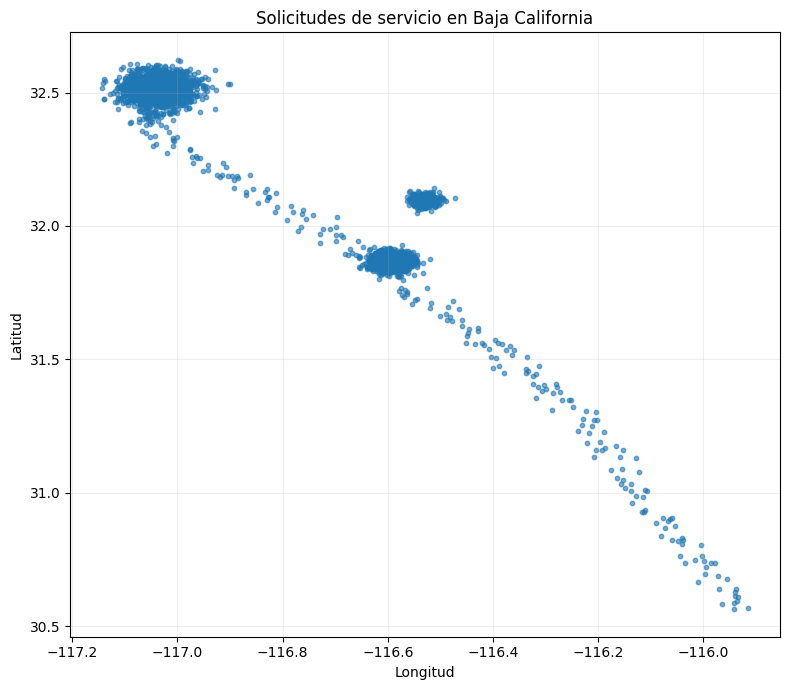

In [4]:
plt.figure(figsize=(8, 7))
plt.scatter(df["Longitud"], df["Latitud"], s=10, alpha=0.6)
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.title("Solicitudes de servicio en Baja California")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Fase 2 - Misión estratégica

La mesa directiva aprobó el presupuesto para construir 3 grandes Centros de Distribución (Cedis) en el estado. Necesitan saber exactamente dónde ubicarlos para que queden en el centro geográfico de la demanda general, minimizando los kilómetros de viaje hacia cualquier punto.

- El Algoritmo: ¿Qué algoritmo de los vistos en clase se adecua más a este problema? **R =** Kmeans
- El Entregable: Un gráfico de dispersión pintando los 3 clústeres. Extraigan las coordenadas de los cluster_centers_ y grafíquenlos como "X" gigantes sobre el mapa.

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)

centros = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=["Latitud", "Longitud"]
)
centros.index.name = "Cluster"
centros["Solicitudes"] = df["Cluster_KMeans"].value_counts().sort_index()
centros.round(5)

,Latitud,Longitud,Solicitudes
Cluster,,,
0,32.50632,-117.03496,1611
1,31.04054,-116.13803,95
2,31.91235,-116.58073,1394


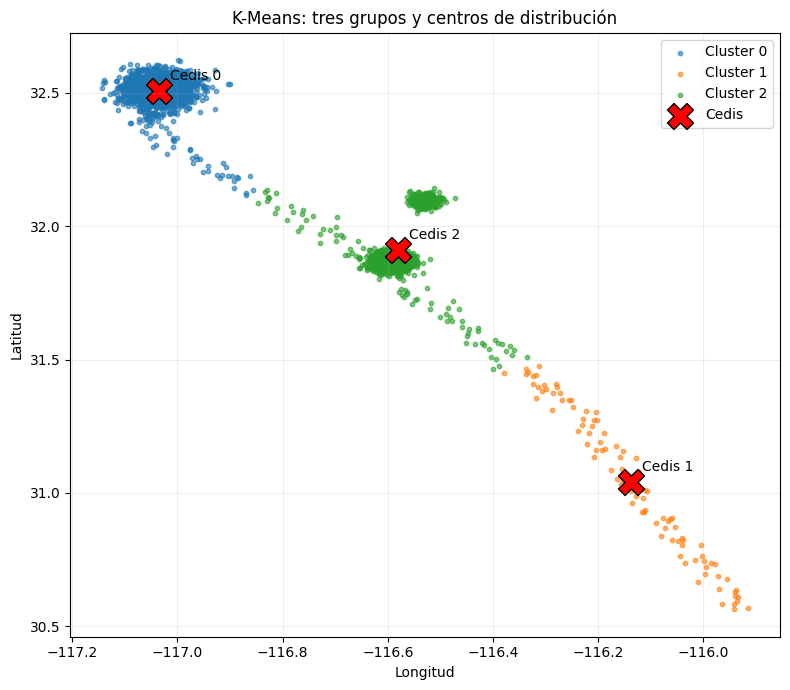

In [6]:
colores = ["tab:blue", "tab:orange", "tab:green"]

plt.figure(figsize=(8, 7))
for grupo in range(3):
    puntos = df[df["Cluster_KMeans"] == grupo]
    plt.scatter(puntos["Longitud"], puntos["Latitud"],
                s=10, alpha=0.6, color=colores[grupo], label=f"Cluster {grupo}")

plt.scatter(centros["Longitud"], centros["Latitud"],
            marker="X", s=350, color="red", edgecolors="black", label="Cedis")
for grupo, centro in centros.iterrows():
    plt.annotate(f"Cedis {grupo}", (centro["Longitud"], centro["Latitud"]),
                 xytext=(8, 8), textcoords="offset points")

plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.title("K-Means: tres grupos y centros de distribución")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

  **¿Dónde colocó el algoritmo que seleccionaron las Cedis?**

> (de norte a sur) el primero se encuentra por la zona de Tijuana, el segundo por ensenada y el tercero por el sur

  **¿Consideran que sus localizaciones hacen sentido?**

> Hasta cierto punto sí tienen sentido porque las primeras dos tratan de abarcar zonas con mucho tráfico de servicios de forma uniforme o acorde mientras que el tercero se va por todas las solicitudes del sur, que están realmente más alejadas de las norteñas. En si sí se está cumpliendo el objetivo de 3 centros distribuidos, pero en cuanto a que tanto conviene la ubicación del tercer centro ya es necesario discutirlo con el negocio. Lógicamente tienen sentido pero ya dentro del negocio no.
  
  **¿Por qué la matemática de este algoritmo provocó esto?**

> K-Means asigna todos los puntos a un grupo y coloca cada centro en el promedio de sus coordenadas. Busca reducir la suma de las distancias entre los puntos y su centro. Por eso las solicitudes más alejadas pesan bastante en el resultado. Aunque hay pocos puntos al sur, darles su propio centro reduce estas distancias.

# Fase 3 - Misión Operativa (Mapa de Tráfico y Zonas Calientes)

Los choferes se están quejando de que hacen viajes de 2 horas para entregar un solo paquete a un rancho aislado en la carretera (ruido/anomalías), alejándolos de la zona urbana donde hay dinero. Necesitan un mapa táctico que aísle las ciudades principales (Alta Densidad) y descarte matemáticamente las zonas rurales dispersas.

- El Algoritmo: Seleccionen el algoritmo que mejor se adecue a este problema, recuerden que el objetivo es localizar 3 manchas urbanas.
- El Entregable: Un gráfico de dispersión coloreado. Los puntos identificados como ruido (Cluster -1) deben pintarse de un color distinto (ej. gris) para demostrar que el algoritmo los ignoró.


In [7]:
pruebas = []

for eps in [0.03, 0.08, 0.40]:
    etiquetas = DBSCAN(eps=eps, min_samples=20).fit_predict(X_scaled)
    pruebas.append({
        "eps": eps,
        "min_samples": 20,
        "Clusters sin ruido": len(set(etiquetas) - {-1}),
        "Puntos de ruido": int((etiquetas == -1).sum())
    })

pd.DataFrame(pruebas)

,eps,min_samples,Clusters sin ruido,Puntos de ruido
0,0.03,20,3,703
1,0.08,20,3,232
2,0.40,20,1,0


In [8]:
dbscan = DBSCAN(eps=0.08, min_samples=20)
df["Cluster_DBSCAN"] = dbscan.fit_predict(X_scaled)

grupos = sorted(set(df["Cluster_DBSCAN"]) - {-1})
cantidad_ruido = (df["Cluster_DBSCAN"] == -1).sum()

print("Clusters encontrados:", len(grupos))
print("Solicitudes marcadas como ruido:", cantidad_ruido)

Clusters encontrados: 3
Solicitudes marcadas como ruido: 232


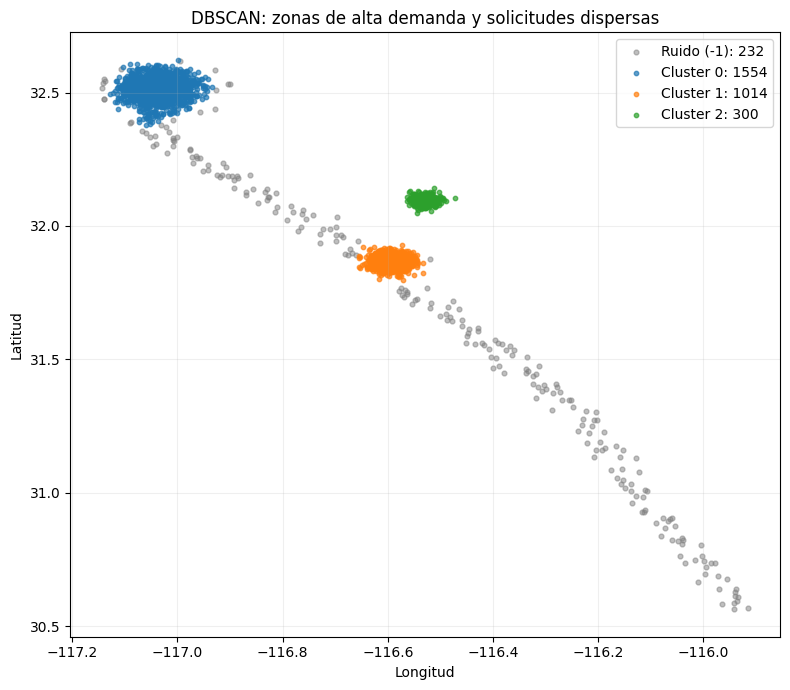

In [9]:
plt.figure(figsize=(8, 7))

ruido = df[df["Cluster_DBSCAN"] == -1]
plt.scatter(ruido["Longitud"], ruido["Latitud"],
            color="gray", s=12, alpha=0.5, label=f"Ruido (-1): {len(ruido)}")

for grupo in grupos:
    puntos = df[df["Cluster_DBSCAN"] == grupo]
    plt.scatter(puntos["Longitud"], puntos["Latitud"],
                s=10, alpha=0.7, color=colores[grupo % len(colores)],
                label=f"Cluster {grupo}: {len(puntos)}")

plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.title("DBSCAN: zonas de alta demanda y solicitudes dispersas")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**¿Usaron el mismo algoritmo que en la misión anterior?**
> Nop, nos pasamos a uno basado en densidades (DBSCAN)

**¿De no ser así, porqué se comportaron diferentes?**
> DBSCAN busca puntos con sufienciete densidad y deja como ruido los puntos que no quedan dnetro de estos lugares, mientras que kmeans lo utilizamos para identificar un número especifico de cedis y asignar TODAS las solicitudes a estos, tomamos todos los datos en cuenta.

**¿A qué ciudades reales corresponden las 3 manchas urbanas que encontró su algoritmo?**
> Tijuana, Ensenada y Valle de Guadalupe

